# Analyze a Saved Architecture Comparison Run

This notebook loads one saved run from `results/` and creates a compact, student-friendly analysis of the holdout results.

It focuses on two kinds of figures:

1. For each test function, one `2 x 2` comparison figure with:
   - `MAPE` results
   - runtime results
   - `R^2` results
   - `MAPE` vs `R^2`
2. Learning-behaviour figures based on the saved history files, using only:
   - train mean
   - validation mean
   - a confidence band (`mean +/- 1 std`)

The goal is to make the comparisons easy to read without too much clutter.


## Setup

Set the run name in the next cell. The notebook then reads the saved summary CSV and the history JSON files for that run.


In [1]:
from pathlib import Path
import json
import os
import re

mpl_config = Path("/tmp/matplotlib")
mpl_config.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_config))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


In [2]:
RUN_NAME = "slurm_138915"
SUMMARY_FILE = "architecture_comparison.csv"
SHOW_FUNCTIONS = None  # Example: ["ackley", "rastrigin"]
SHOW_MODELS = None     # Example: ["CMLP", "GHR"]
FIG_DPI = 120


In [3]:
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())
results_root = repo_root / "results"
available_runs = sorted(path.name for path in results_root.iterdir() if path.is_dir())
run_dir = results_root / RUN_NAME
summary_path = run_dir / SUMMARY_FILE
history_dir = run_dir / "history"

if not run_dir.exists():
    raise FileNotFoundError(f"Run directory not found: {run_dir}")
if not summary_path.exists():
    raise FileNotFoundError(f"Summary file not found: {summary_path}")

print(f"Repo root: {repo_root}")
print(f"Available runs: {available_runs}")
print(f"Selected run: {run_dir}")
print(f"Summary file: {summary_path}")
print(f"History directory exists: {history_dir.exists()}")


Repo root: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN
Available runs: ['slurm_138915']
Selected run: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/results/slurm_138915
Summary file: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/results/slurm_138915/architecture_comparison.csv
History directory exists: True


In [4]:
summary_df = pd.read_csv(summary_path)

if SHOW_FUNCTIONS is not None:
    summary_df = summary_df[summary_df["test_function"].isin(SHOW_FUNCTIONS)].copy()
if SHOW_MODELS is not None:
    summary_df = summary_df[summary_df["algorithm"].isin(SHOW_MODELS)].copy()

if summary_df.empty:
    raise ValueError("The selected filters removed all rows.")

preferred_function_order = ["ackley", "griewank", "rastrigin", "schwefel"]
function_order = [name for name in preferred_function_order if name in set(summary_df["test_function"])]
function_order += [name for name in sorted(summary_df["test_function"].unique()) if name not in function_order]

preferred_model_order = ["CMLP", "GHR", "Arena", "Nitta"]
model_order = [name for name in preferred_model_order if name in set(summary_df["algorithm"])]
model_order += [name for name in sorted(summary_df["algorithm"].unique()) if name not in model_order]

summary_df["test_function"] = pd.Categorical(summary_df["test_function"], categories=function_order, ordered=True)
summary_df["algorithm"] = pd.Categorical(summary_df["algorithm"], categories=model_order, ordered=True)
summary_df = summary_df.sort_values(["test_function", "algorithm", "repetition"]).reset_index(drop=True)

summary_df


,repetition,algorithm,test_function,learning_rate,optimizer,activation,batch_size,test_quaternion_mae,test_mse,test_mae,test_mape,test_r2,epochs,runtime_seconds
0,1,CMLP,ackley,0.004734,Adadelta,sigmoid,1,0.378971,0.308490,0.377834,0.019282,0.766106,5,302.736058
1,2,CMLP,ackley,0.004734,Adadelta,sigmoid,1,0.436232,0.349718,0.417415,0.021158,0.734847,5,302.319673
2,1,GHR,ackley,0.001826,SGD,tanh,1,0.720016,1.377420,0.715831,0.037639,-0.044345,5,430.344769
3,2,GHR,ackley,0.001826,SGD,tanh,1,0.715060,1.391580,0.714951,0.037647,-0.055081,5,430.058981
4,1,CMLP,griewank,0.000483,Adadelta,swish,1,3.710737,21.022938,3.233856,0.027510,0.992681,5,305.915248
5,2,CMLP,griewank,0.000483,Adadelta,swish,1,2.934761,12.508799,2.658812,0.023438,0.995645,5,305.594811
6,1,GHR,griewank,0.000483,Adadelta,swish,1,3.744687,16.225405,2.742762,0.022767,0.994351,5,496.572415
7,2,GHR,griewank,0.000483,Adadelta,swish,1,3.273751,13.120440,2.742340,0.026490,0.995432,5,496.535557
8,1,CMLP,rastrigin,0.000483,Adadelta,swish,1,12.141574,209.566681,11.778305,0.183128,0.489447,5,305.808257
9,2,CMLP,rastrigin,0.000483,Adadelta,swish,1,11.860564,207.299271,11.628201,0.176037,0.494971,5,305.618610


## Summary Tables

`MAPE` and `R^2` come from the holdout test set. Runtime is the training runtime saved for each run.

The first table is a tidy summary per function and model. The second table is a pivoted version for quicker side-by-side comparison.


In [5]:
def _format_mean_std(mean_value: float, std_value: float, digits: int = 4) -> str:
    if pd.isna(std_value):
        std_value = 0.0
    return f"{mean_value:.{digits}f} +/- {std_value:.{digits}f}"

summary_stats = (
    summary_df.groupby(["test_function", "algorithm"], observed=True)
    .agg(
        runs=("repetition", "count"),
        mape_mean=("test_mape", "mean"),
        mape_std=("test_mape", "std"),
        r2_mean=("test_r2", "mean"),
        r2_std=("test_r2", "std"),
        runtime_mean=("runtime_seconds", "mean"),
        runtime_std=("runtime_seconds", "std"),
    )
    .reset_index()
)

summary_stats["MAPE"] = summary_stats.apply(lambda row: _format_mean_std(row.mape_mean, row.mape_std), axis=1)
summary_stats["R^2"] = summary_stats.apply(lambda row: _format_mean_std(row.r2_mean, row.r2_std), axis=1)
summary_stats["Runtime (s)"] = summary_stats.apply(lambda row: _format_mean_std(row.runtime_mean, row.runtime_std, digits=2), axis=1)

tidy_table = summary_stats[["test_function", "algorithm", "runs", "MAPE", "R^2", "Runtime (s)"]]
display(tidy_table)

pivot_table = (
    summary_stats.set_index(["test_function", "algorithm"])[["MAPE", "R^2", "Runtime (s)"]]
    .unstack("algorithm")
)
display(pivot_table)


,test_function,algorithm,runs,MAPE,R^2,Runtime (s)
0,ackley,CMLP,2,0.0202 +/- 0.0013,0.7505 +/- 0.0221,302.53 +/- 0.29
1,ackley,GHR,2,0.0376 +/- 0.0000,-0.0497 +/- 0.0076,430.20 +/- 0.20
2,griewank,CMLP,2,0.0255 +/- 0.0029,0.9942 +/- 0.0021,305.76 +/- 0.23
3,griewank,GHR,2,0.0246 +/- 0.0026,0.9949 +/- 0.0008,496.55 +/- 0.03
4,rastrigin,CMLP,2,0.1796 +/- 0.0050,0.4922 +/- 0.0039,305.71 +/- 0.13
5,rastrigin,GHR,2,0.1800 +/- 0.0039,0.4935 +/- 0.0085,497.15 +/- 0.38
6,schwefel,CMLP,2,0.2025 +/- 0.0025,0.1024 +/- 0.0009,305.61 +/- 0.33
7,schwefel,GHR,2,0.2024 +/- 0.0013,0.1106 +/- 0.0071,511.42 +/- 0.27


MAPE                                   R^2  \
algorithm                   CMLP                GHR               CMLP   
test_function                                                            
ackley         0.0202 +/- 0.0013  0.0376 +/- 0.0000  0.7505 +/- 0.0221   
griewank       0.0255 +/- 0.0029  0.0246 +/- 0.0026  0.9942 +/- 0.0021   
rastrigin      0.1796 +/- 0.0050  0.1800 +/- 0.0039  0.4922 +/- 0.0039   
schwefel       0.2025 +/- 0.0025  0.2024 +/- 0.0013  0.1024 +/- 0.0009   

                                       Runtime (s)                   
algorithm                     GHR             CMLP              GHR  
test_function                                                        
ackley         -0.0497 +/- 0.0076  302.53 +/- 0.29  430.20 +/- 0.20  
griewank        0.9949 +/- 0.0008  305.76 +/- 0.23  496.55 +/- 0.03  
rastrigin       0.4935 +/- 0.0085  305.71 +/- 0.13  497.15 +/- 0.38  
schwefel        0.1106 +/- 0.0071  305.61 +/- 0.33  511.42 +/- 0.27

## Plot Helpers

The next helpers keep the figures visually consistent and easy to read. Every model gets the same color in every plot.


In [6]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = FIG_DPI

palette = plt.get_cmap("tab10")
model_colors = {model: palette(idx) for idx, model in enumerate(model_order)}


def _present_models(df: pd.DataFrame) -> list[str]:
    return [model for model in model_order if model in set(df["algorithm"])]


def _boxplot_with_points(ax, df: pd.DataFrame, metric_col: str, ylabel: str, title: str):
    present_models = _present_models(df)
    values = [df.loc[df["algorithm"] == model, metric_col].to_numpy() for model in present_models]
    positions = np.arange(1, len(present_models) + 1)

    box = ax.boxplot(values, positions=positions, widths=0.6, patch_artist=True, tick_labels=present_models)
    for patch, model in zip(box["boxes"], present_models):
        patch.set_facecolor(model_colors[model])
        patch.set_alpha(0.45)
    for median in box["medians"]:
        median.set_color("black")
        median.set_linewidth(1.6)

    for xpos, model, series in zip(positions, present_models, values):
        if len(series) == 0:
            continue
        offsets = np.linspace(-0.07, 0.07, num=len(series)) if len(series) > 1 else np.array([0.0])
        ax.scatter(
            np.full(len(series), xpos) + offsets,
            series,
            color=model_colors[model],
            edgecolor="black",
            linewidth=0.5,
            s=34,
            zorder=3,
        )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(ylabel)


def plot_function_comparison(function_name: str, df: pd.DataFrame):
    function_df = df[df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), squeeze=False)
    axes = axes.ravel()

    _boxplot_with_points(
        axes[0],
        function_df,
        metric_col="test_mape",
        ylabel="MAPE",
        title=f"{function_name.capitalize()} MAPE Results (lower is better)",
    )
    _boxplot_with_points(
        axes[1],
        function_df,
        metric_col="runtime_seconds",
        ylabel="Runtime (seconds)",
        title=f"{function_name.capitalize()} Runtime Results (lower is better)",
    )
    _boxplot_with_points(
        axes[2],
        function_df,
        metric_col="test_r2",
        ylabel="R^2",
        title=f"{function_name.capitalize()} R^2 Results (higher is better)",
    )

    for model in present_models:
        model_df = function_df[function_df["algorithm"] == model]
        axes[3].scatter(
            model_df["test_mape"],
            model_df["test_r2"],
            color=model_colors[model],
            s=60,
            alpha=0.9,
            edgecolor="black",
            linewidth=0.5,
            label=model,
        )
    axes[3].set_title(f"{function_name.capitalize()} MAPE vs R^2")
    axes[3].set_xlabel("MAPE")
    axes[3].set_ylabel("R^2")
    axes[3].legend(title="Model")

    fig.suptitle(f"Holdout Comparison for {function_name.capitalize()}", fontsize=15, y=1.02)
    fig.tight_layout()
    return fig


## Plot Type 1: Holdout Comparison per Function

Read each figure like this:

- the first three panels compare the holdout distributions across models
- the last panel shows the trade-off between `MAPE` and `R^2`
- better models are usually toward **low MAPE**, **low runtime**, and **high `R^2`**


### Ackley

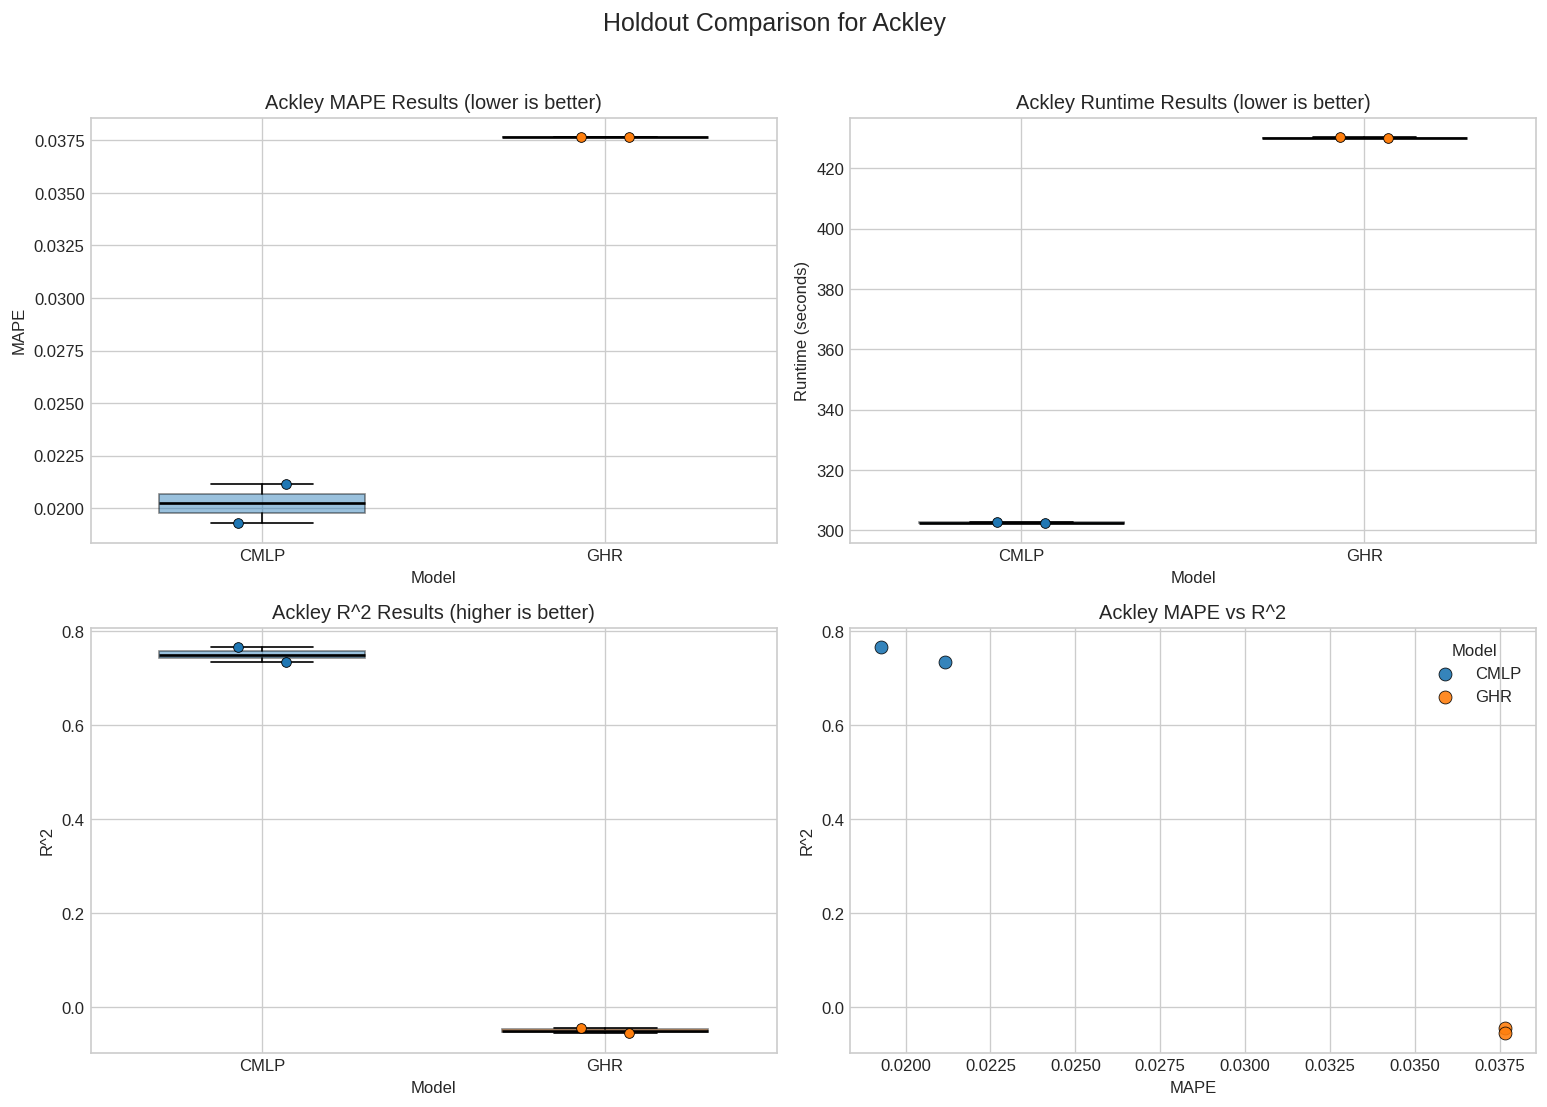

### Griewank

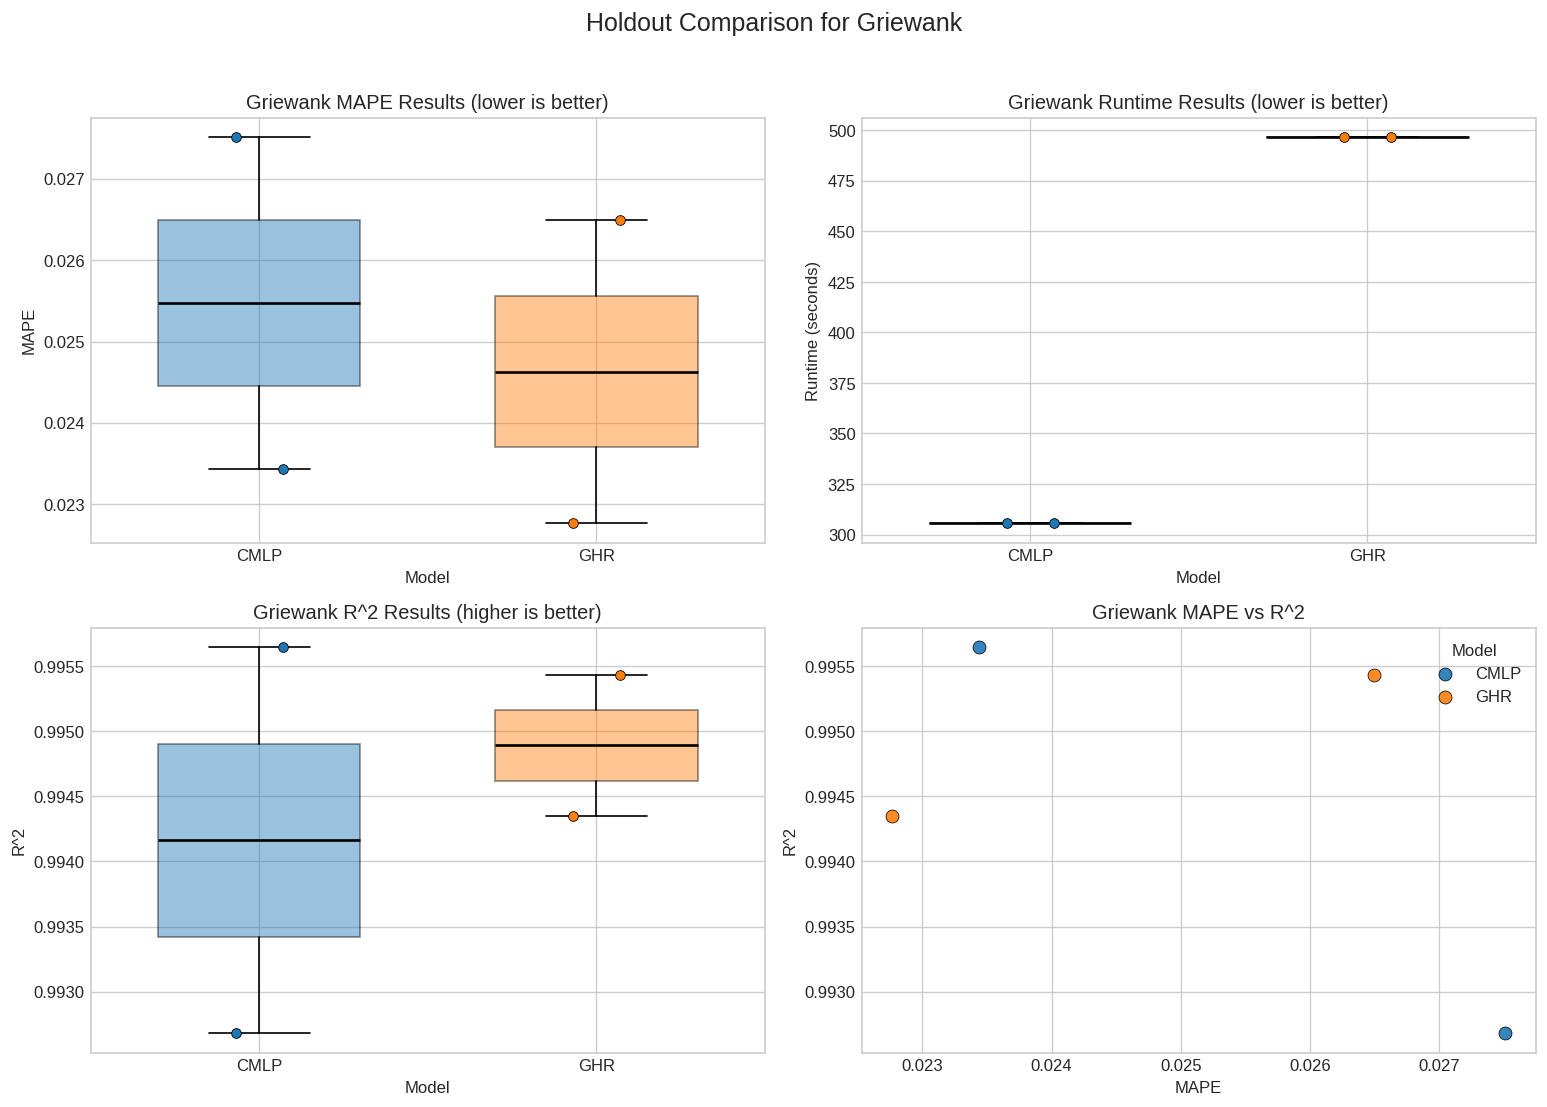

### Rastrigin

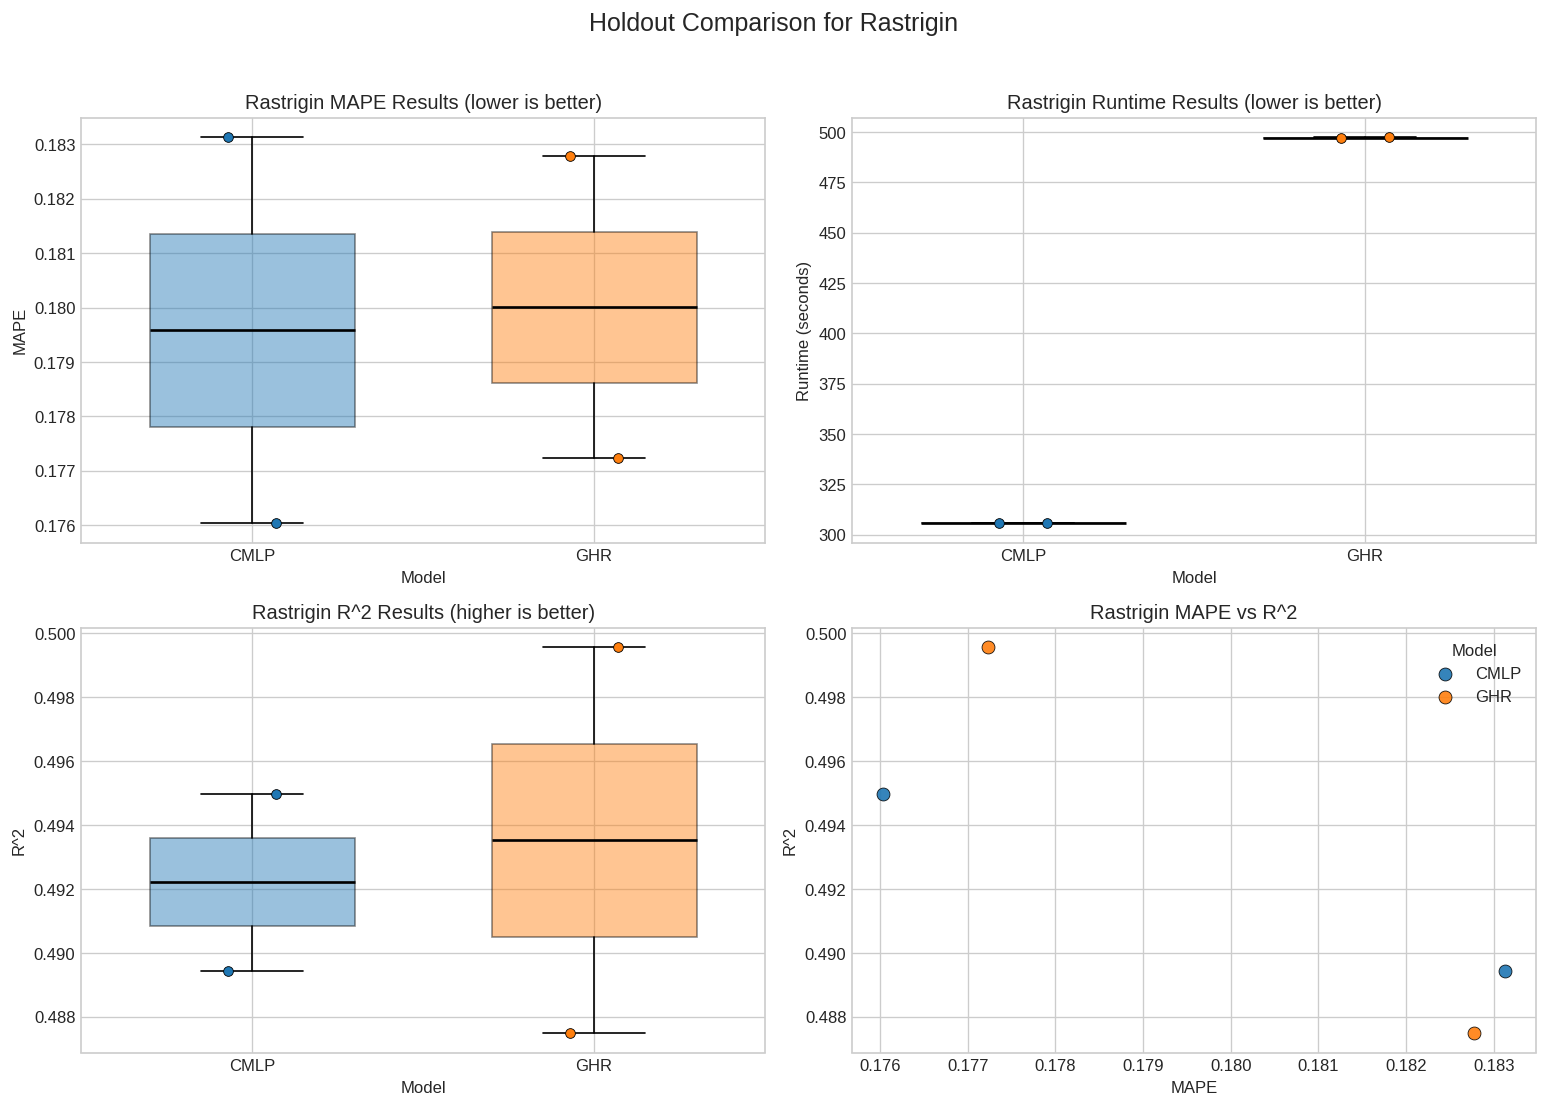

### Schwefel

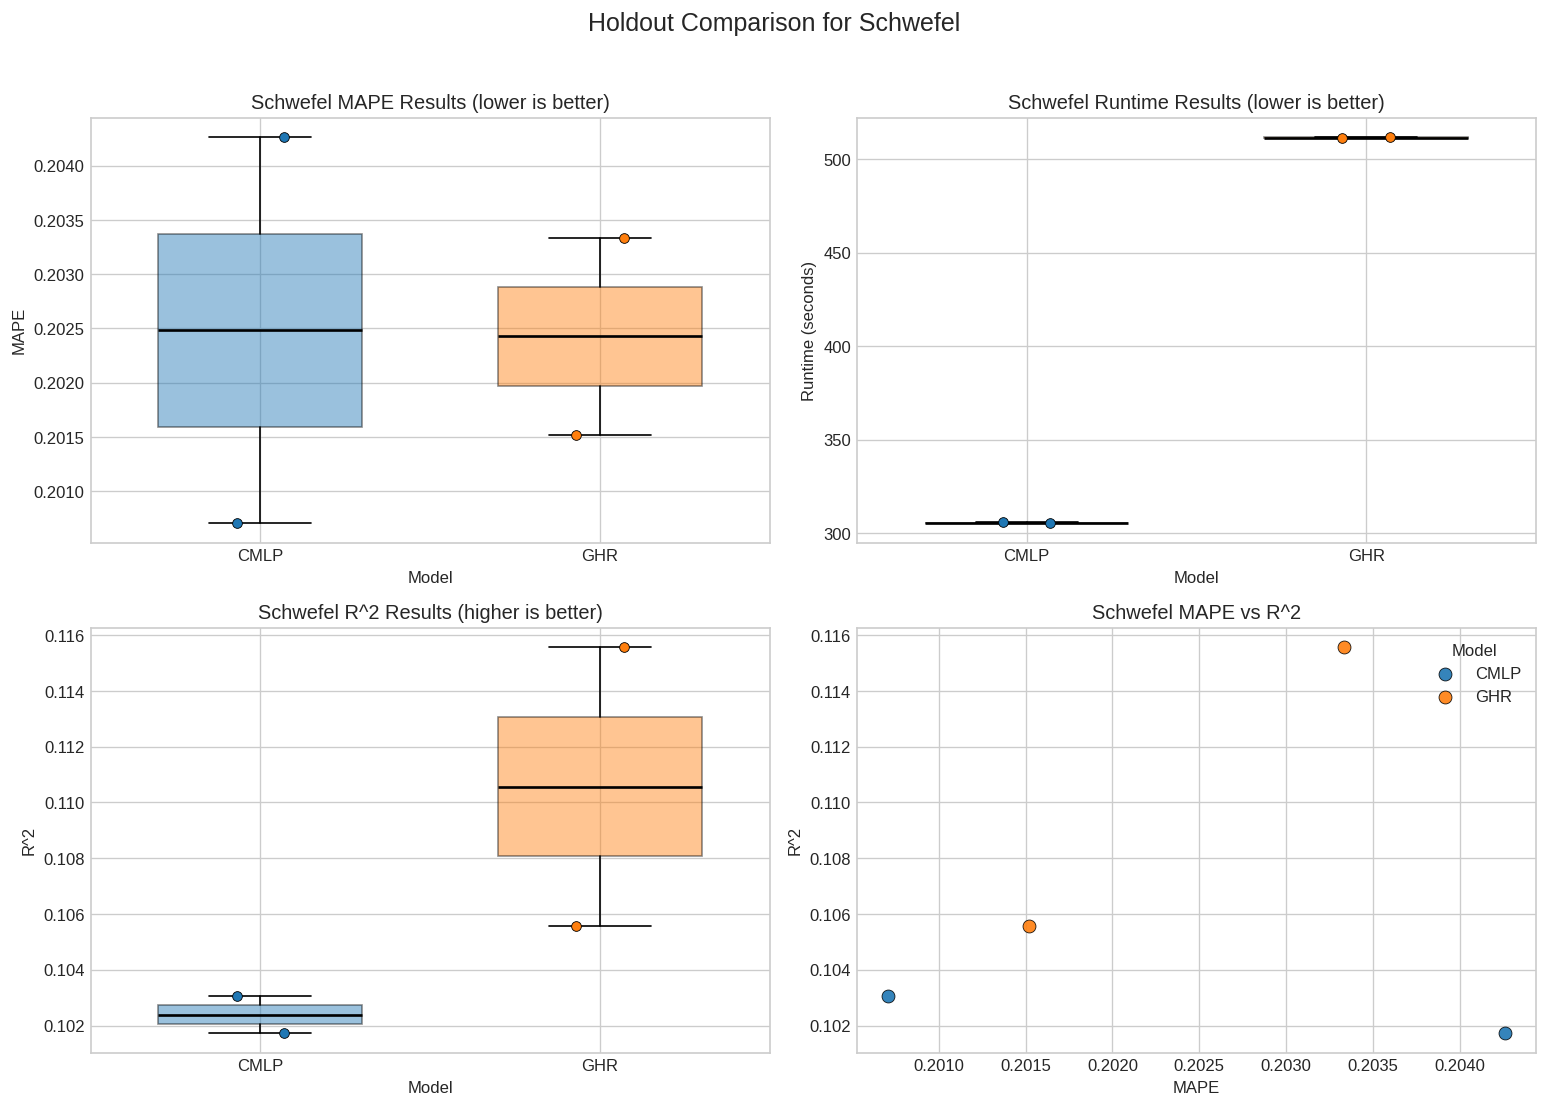

In [7]:
for function_name in function_order:
    display(Markdown(f"### {function_name.capitalize()}"))
    plot_function_comparison(function_name, summary_df)
    plt.show()


## Learning Behaviour Data

The saved history files contain per-epoch:

- training quaternion MAE
- validation quaternion MAE
- training MAPE
- training `R^2`

For clean learning plots, we will only use training and validation quaternion MAE and aggregate them across repetitions.


In [8]:
history_pattern = re.compile(r"(?P<function>.+)_(?P<algorithm>[^_]+)_rep(?P<rep>\d+)\.json")

history_rows = []
for history_path in sorted(history_dir.glob("*.json")):
    match = history_pattern.fullmatch(history_path.name)
    if match is None:
        continue
    function_name = match.group("function")
    algorithm_name = match.group("algorithm").upper()
    repetition = int(match.group("rep"))
    payload = json.loads(history_path.read_text())
    epochs_ran = int(payload.get("epochs_ran", len(payload.get("quaternion_mae", []))))

    for epoch_idx in range(epochs_ran):
        history_rows.append(
            {
                "test_function": function_name,
                "algorithm": algorithm_name,
                "repetition": repetition,
                "epoch": epoch_idx + 1,
                "train_quaternion_mae": payload["quaternion_mae"][epoch_idx],
                "validation_quaternion_mae": payload["validation_quaternion_mae"][epoch_idx],
            }
        )

history_df = pd.DataFrame(history_rows)

if not history_df.empty:
    history_df["test_function"] = pd.Categorical(history_df["test_function"], categories=function_order, ordered=True)
    history_df["algorithm"] = pd.Categorical(history_df["algorithm"], categories=model_order, ordered=True)
    history_df = history_df.sort_values(["test_function", "algorithm", "repetition", "epoch"]).reset_index(drop=True)

history_df.head()


,test_function,algorithm,repetition,epoch,train_quaternion_mae,validation_quaternion_mae
0,ackley,CMLP,1,1,0.699826,0.712712
1,ackley,CMLP,1,2,0.701978,0.714030
2,ackley,CMLP,1,3,0.590845,0.602397
3,ackley,CMLP,1,4,0.374565,0.382389
4,ackley,CMLP,1,5,0.481498,0.483601


In [9]:
def _curve_stats(subset: pd.DataFrame, value_col: str) -> pd.DataFrame:
    stats = (
        subset.groupby("epoch", observed=True)[value_col]
        .agg(["mean", "std"])
        .reset_index()
        .rename(columns={"mean": f"{value_col}_mean", "std": f"{value_col}_std"})
    )
    stats[f"{value_col}_std"] = stats[f"{value_col}_std"].fillna(0.0)
    return stats


def plot_learning_behaviour_for_function(function_name: str, history_df: pd.DataFrame):
    function_df = history_df[history_df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)
    fig, axes = plt.subplots(1, len(present_models), figsize=(6.2 * len(present_models), 4.6), squeeze=False)
    axes = axes.ravel()

    train_color = "tab:blue"
    val_color = "tab:orange"

    for ax, model_name in zip(axes, present_models):
        subset = function_df[function_df["algorithm"] == model_name]
        train_stats = _curve_stats(subset, "train_quaternion_mae")
        val_stats = _curve_stats(subset, "validation_quaternion_mae")

        ax.plot(train_stats["epoch"], train_stats["train_quaternion_mae_mean"], color=train_color, linewidth=2.2, label="Train mean")
        ax.fill_between(
            train_stats["epoch"],
            train_stats["train_quaternion_mae_mean"] - train_stats["train_quaternion_mae_std"],
            train_stats["train_quaternion_mae_mean"] + train_stats["train_quaternion_mae_std"],
            color=train_color,
            alpha=0.18,
            label="Train +/- 1 std",
        )

        ax.plot(val_stats["epoch"], val_stats["validation_quaternion_mae_mean"], color=val_color, linewidth=2.2, linestyle="--", label="Validation mean")
        ax.fill_between(
            val_stats["epoch"],
            val_stats["validation_quaternion_mae_mean"] - val_stats["validation_quaternion_mae_std"],
            val_stats["validation_quaternion_mae_mean"] + val_stats["validation_quaternion_mae_std"],
            color=val_color,
            alpha=0.18,
            label="Validation +/- 1 std",
        )

        ax.set_title(f"{function_name.capitalize()} - {model_name}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Quaternion MAE")

    legend_handles = [
        Line2D([0], [0], color=train_color, linewidth=2.2, label="Train mean"),
        Line2D([0], [0], color=val_color, linewidth=2.2, linestyle="--", label="Validation mean"),
        Line2D([0], [0], color=train_color, linewidth=8, alpha=0.18, label="Train +/- 1 std"),
        Line2D([0], [0], color=val_color, linewidth=8, alpha=0.18, label="Validation +/- 1 std"),
    ]
    fig.legend(handles=legend_handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
    fig.suptitle(f"Learning Behaviour for {function_name.capitalize()}", fontsize=15, y=1.08)
    fig.tight_layout()
    return fig


## Plot Type 2: Learning Behaviour

These plots are intentionally less cluttered than before:

- no single-run lines
- solid blue line = train mean
- dashed orange line = validation mean
- shaded band = `mean +/- 1 std` across repetitions

This makes it much easier to see the general trend of each model.


### Ackley

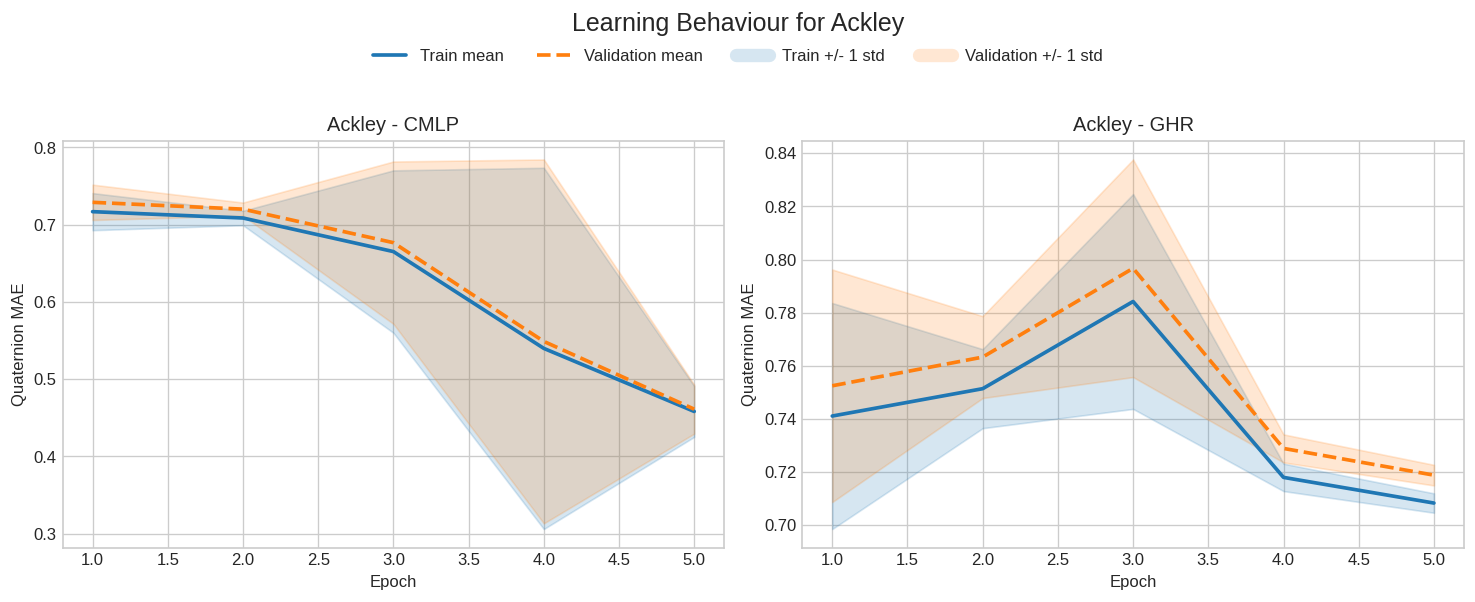

### Griewank

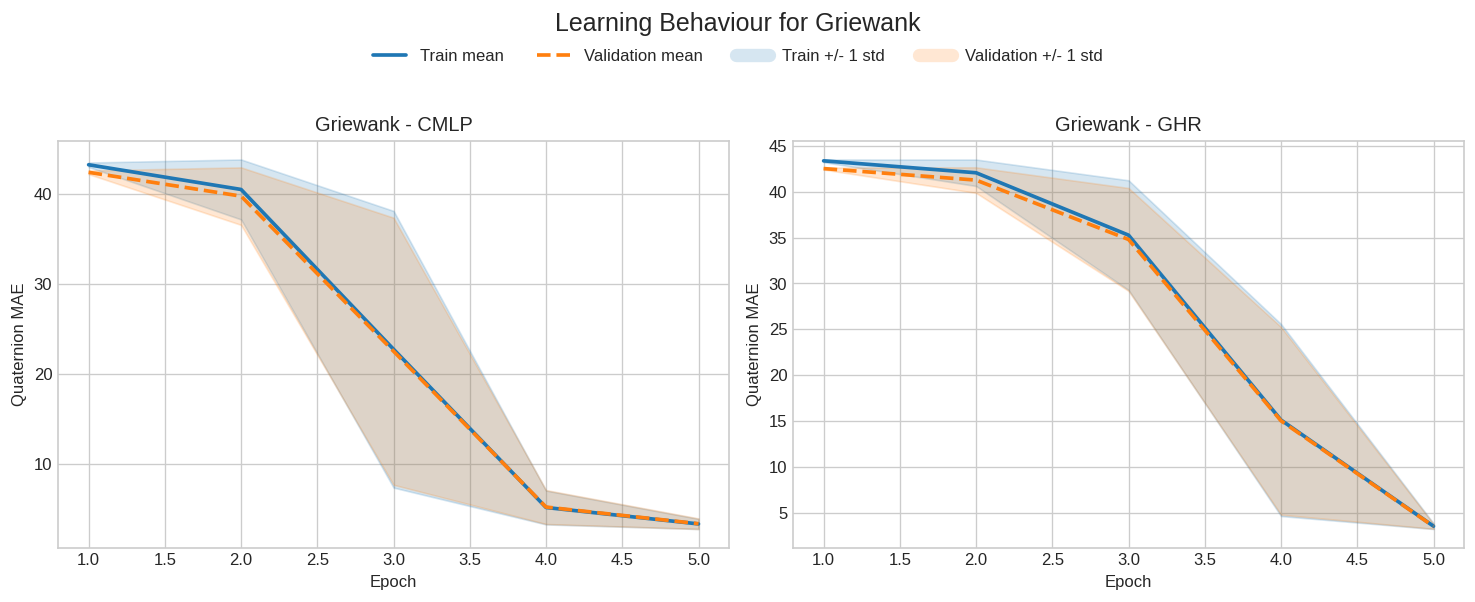

### Rastrigin

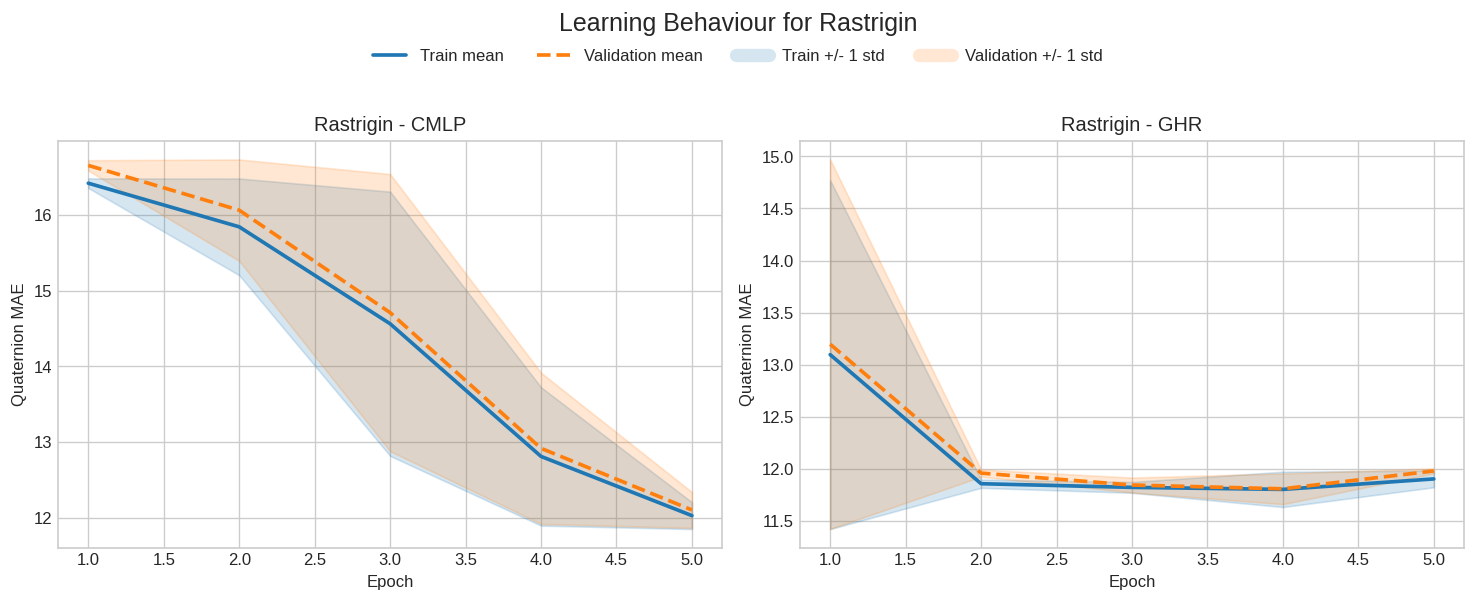

### Schwefel

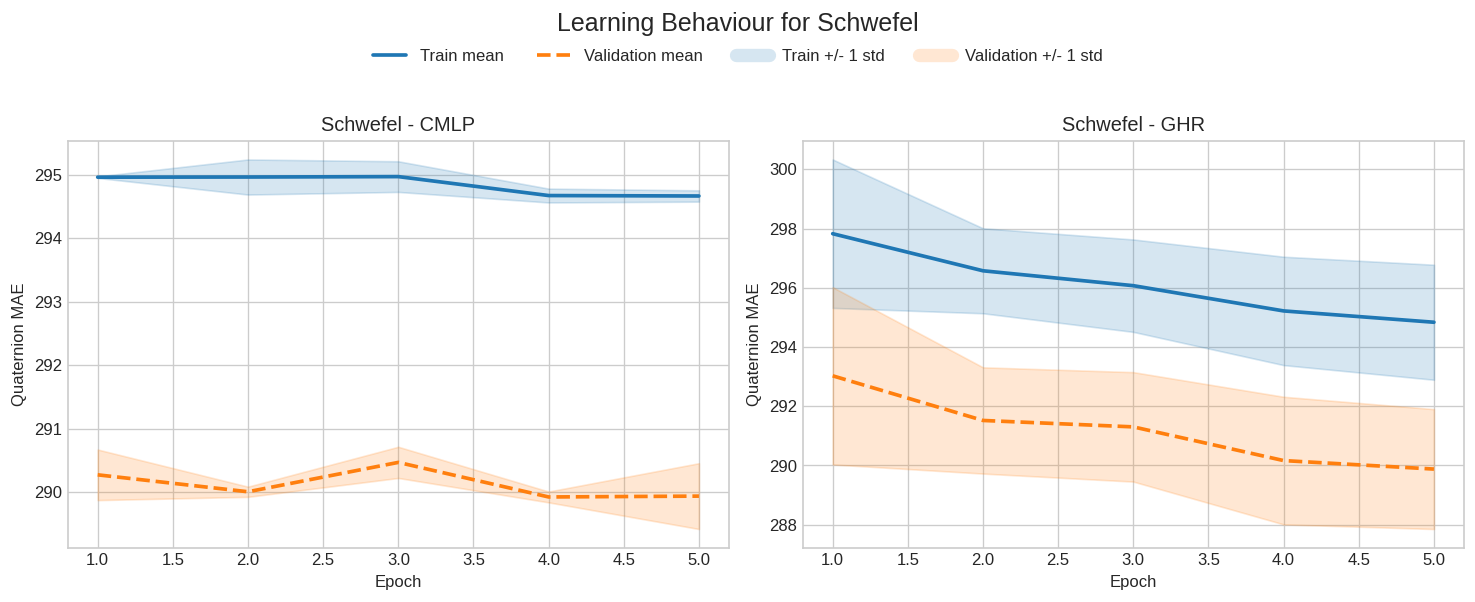

In [10]:
for function_name in function_order:
    display(Markdown(f"### {function_name.capitalize()}"))
    plot_learning_behaviour_for_function(function_name, history_df)
    plt.show()
